## The Big Project begins!!

# "THE PRICE IS RIGHT" Capstone Project

This week - build a model that predicts how much something costs from a description, based on a scrape of Amazon data

# Order of play

DAY 1: Data Curation  
DAY 2: Data Pre-processing  
DAY 3: Evaluation, Baselines, Traditional ML  
DAY 4: Deep Learning and LLMs  
DAY 5: Fine-tuning a Frontier Model  

## DAY 1: Data Curation

Today we'll scrub our dataset and curate our data

The dataset is here:  
https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023

And the folder with all the product datasets is here:  
https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/tree/main/raw/meta_categories

<table style="margin: 0; text-align: left;">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/business.jpg" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#181;">Business value of Data Curation</h2>
            <span style="color:#181;">Data Curation can be considered the less glamorous work of a Data Scientist. I say that's nonsense!
            This is where the science happens - what could be more glamorous than that?! R&D with your
            dataset can often have a greater impact on performance than the fashionable 'hyper-parameter optimization' that we do later.
            So: prepare for Quality Time with Data Quality.</span>
        </td>
    </tr>
</table>

In [1]:
# imports

import os
from dotenv import load_dotenv
from huggingface_hub import login
from datasets import load_dataset
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import numpy as np
import random
from pricer.items import Item
from pricer.parser import parse
load_dotenv(override=True)

True

In [2]:
# Log in to HuggingFace - if you get a "Note" about Environment variable being set, ignore it

from huggingface_hub import constants
constants.HF_HUB_OFFLINE = False

hf_token = os.environ['HF_TOKEN']
login(hf_token, add_to_git_credential=False)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


## Load our dataset

In the next cell, we load in the dataset from huggingface.

If this gives you an error like "trust_remote_code is no longer supported", then please run this command in a new cell: `!uv add --upgrade datasets==3.6.0` and then restart the Kernel, and try again.

In [ ]:
import json
import tempfile
from datasets import config

source_file = r"C:\xampp\htdocs\Python\llm_engineering\week6\data\amazon_data_set_hf\appliance\meta_Appliances.jsonl"

constants.HF_HUB_OFFLINE = False
config.HF_DATASETS_OFFLINE = False

valid_lines = 0
invalid_lines = []

with open(source_file, "r", encoding="utf-8") as source, tempfile.NamedTemporaryFile(
    mode="w", encoding="utf-8", suffix=".jsonl", delete=False
) as cleaned:
    cleaned_file = cleaned.name
    for line_number, line in enumerate(source, start=1):
        try:
            record = json.loads(line)
            if not isinstance(record, dict):
                raise ValueError("JSON record is not an object")
            cleaned.write(json.dumps(record, ensure_ascii=False) + "\n")
            valid_lines += 1
        except (json.JSONDecodeError, ValueError):
            invalid_lines.append(line_number)

print(f"Valid records: {valid_lines:,}; skipped lines: {len(invalid_lines):,}")
if invalid_lines:
    print(f"First skipped line numbers: {invalid_lines[:10]}")

dataset = load_dataset("json", data_files=cleaned_file, split="train", streaming=True)

Valid records: 94,327; skipped lines: 0


In [4]:
print(f"Number of Appliances: {valid_lines:,}")

Number of Appliances: 94,327


In [5]:
# Investigate a particular datapoint

next(iter(dataset.skip(6)))


{'main_category': 'Appliances',
 'title': 'WD12X10327 Rack Roller and stud assembly Kit (4 Pack) by AMI PARTS Replaces AP4980629 PS3486910 1811003',
 'average_rating': 4.6,
 'rating_number': 323,
 'features': ['【PARTS NUMBER】The WD12X10327 dishwasher top rack wheels and stud assembly Kit （4 pcs）',
  '【SCOPE OF APPLICATION】The dishwasher works with most top name brands,If you are not sure if part is correct, ask us in Customer questions & answers section or visiting the AMI PARTS storefront.We’re happy to help ensure you select the correct part for your Rack Roller and stud',
  '【REPLACES PART】1811003, AP4980629, WD12X0330, WD12X0356, WD12X0357, WD12X0383, WD12X0385, WD12X10327, WD12X330, WD12X356, WD12X357, WD12X383, WD12X385',
  '【FIXES SYMPTOMS】Door won’t close | Not cleaning dishes properly | Noisy | Door latch failure',
  '【QUALITY WARRANTY】The replacement part is made from durable high quality material and well-tested by manufacturer.For any reason you’re not satisfied,you can ask

In [6]:

# What's the most expensive item?

max_price = 0
max_item = None

for datapoint in tqdm(dataset):
    if datapoint.get("price") is None:
        continue
    try:
        price = float(datapoint["price"])
        if price > max_price:
            max_item = datapoint
            max_price = price
    except (TypeError, ValueError):
        pass

if max_item is not None:
    print(f"The most expensive item is {max_item['title']} and it costs {max_price:,.2f}")
else:
    print("No items with a valid price were found.")

0it [00:00, ?it/s]

The most expensive item is TurboChef BULLET Rapid Cook Electric Microwave Convection Oven and it costs 21,095.62


This is the closest I can find - looks like it's going at a bargain price!!

https://www.amazon.com/TurboChef-Electric-Countertop-Microwave-Convection/dp/B01D05U9NO/

In [7]:
# Load into Item objects if they have a price range $1-$1000 and enough details

items = []
for datapoint in tqdm(dataset):
    raw_price = datapoint.get("price")
    if not isinstance(raw_price, (int, float, str)):
        continue

    try:
        price = float(raw_price)
    except (TypeError, ValueError):
        continue

    if 1 <= price <= 1000:
        item = parse(datapoint, "Appliances")
        if item is not None:
            items.append(item)
items = [item for item in items if item is not None]
print(f"There are {len(items):,} items from {valid_lines:,} datapoints")

0it [00:00, ?it/s]

There are 46,093 items from 94,327 datapoints


In [8]:
items[0]

<Whirlpool W10918546 Igniter = $25.07>

In [9]:
print(items[0].full)

Whirlpool  Igniter
['Whirlpool Igniter']
['This is a Genuine OEM Replacement Part.']
{"Brand": null, "Model Name": null, "Capacity": null, "Wattage": null, "Voltage": null, "Package Dimensions": null, "Date First Available": "April 19, 2019", "Manufacturer": "Whirlpool", "Item Weight": "1 pounds", "Product Dimensions": "1 x 1 x 1 inches", "Size": null, "Color": null, "Material": null, "Shape": null, "Handle Material": null, "Number of Sets": null, "Is Discontinued By Manufacturer": null, "Item Package Quantity": "1", "Warranty Description": "This is a Genuine OEM Replacement Part.", "Brand Name": null, "Model Info": null, "Material Type": null, "Style": null, "Finish": null, "Mounting Type": null, "Finish Type": null, "Unit Count": null, "Number of Pieces": null, "Pattern": null, "Duration": null, "External Testing Certification": null, "Number Of Pieces": null, "Reusability": null, "Handle Type": null, "Included Components": null, "Finish types": null, "Batteries required": null, "Cou

In [10]:
prices = [item.price for item in items]
lengths = [len(item.full) for item in items]

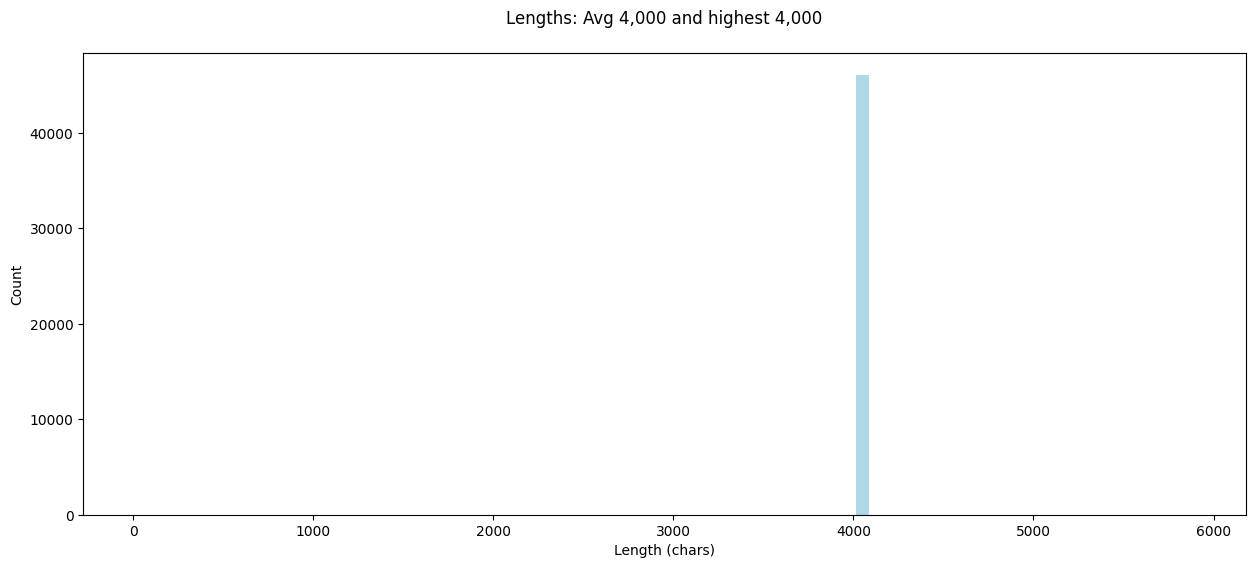

In [11]:
# Plot the distribution of lengths

plt.figure(figsize=(15, 6))
plt.title(f"Lengths: Avg {sum(lengths)/len(lengths):,.0f} and highest {max(lengths):,}\n")
plt.xlabel('Length (chars)')
plt.ylabel('Count')
plt.hist(lengths, rwidth=0.7, color="lightblue", bins=range(0, 6000, 100))
plt.show()

In [12]:
max_length = max(lengths)
max_length_item = items[lengths.index(max_length)]
print(max_length_item.full)


Whirlpool  Igniter
['Whirlpool Igniter']
['This is a Genuine OEM Replacement Part.']
{"Brand": null, "Model Name": null, "Capacity": null, "Wattage": null, "Voltage": null, "Package Dimensions": null, "Date First Available": "April 19, 2019", "Manufacturer": "Whirlpool", "Item Weight": "1 pounds", "Product Dimensions": "1 x 1 x 1 inches", "Size": null, "Color": null, "Material": null, "Shape": null, "Handle Material": null, "Number of Sets": null, "Is Discontinued By Manufacturer": null, "Item Package Quantity": "1", "Warranty Description": "This is a Genuine OEM Replacement Part.", "Brand Name": null, "Model Info": null, "Material Type": null, "Style": null, "Finish": null, "Mounting Type": null, "Finish Type": null, "Unit Count": null, "Number of Pieces": null, "Pattern": null, "Duration": null, "External Testing Certification": null, "Number Of Pieces": null, "Reusability": null, "Handle Type": null, "Included Components": null, "Finish types": null, "Batteries required": null, "Cou

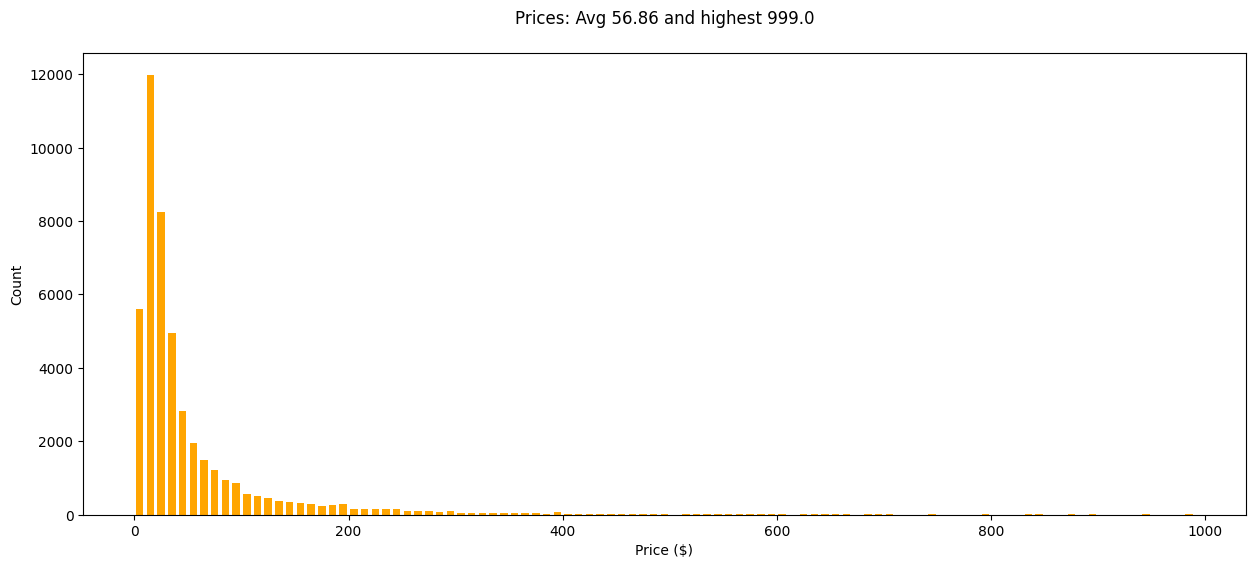

In [13]:
# Plot the distribution of prices
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.2f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="orange", bins=range(0, 1000, 10))
plt.show()

In [14]:
print(items[3].full)

Door Pivot Block - Compatible Kenmore KitchenAid Maytag Whirlpool Refrigerator - Replaces    - Quick DIY Repair Solution
[' Pivot Block For Vernicle Mullion Strip On Door - A high-quality exact equivalent for part numbers , , , , , , and .', 'Compatibility with major brands -  Door Guide is compatible with Whirlpool, Amana, Dacor, Gaggenau, Hardwick, Jenn-Air, Kenmore, KitchenAid, and Maytag.', "Quick DIY repair -  Refrigerator Door Guide Pivot Block Replacement will help if your appliance door doesn't open or close. Wear work gloves to protect your hands during the repair process.", 'Attentive support - If you are uncertain about whether the block fits your refrigerator, we will help. We generally put forth a valiant effort to guarantee you are totally happy with your purchase.', 'High-quality elements -   Pivot Block Replacement meets or exceeds all manufacturer specifications. We provide a 365-day return policy and guarantee 100% money back.']
{"Brand": null, "Model Name": null, "Ca

In [16]:

dataset_names = [
    "Automotive",
    "Electronics",
    "Office_Products",
    "Tools_and_Home_Improvement",
    "Cell_Phones_and_Accessories",
    "Toys_and_Games",
    "Appliances",
    "Musical_Instruments",
]

In [ ]:
from pricer.loaders import ItemLoader

items = []
for dataset_name in dataset_names:
    loader = ItemLoader(dataset_name)
    items.extend(loader.load())

In [ ]:
print(f"A grand total of {len(items):,} items")

In [ ]:
items[1000]

In [ ]:
random.seed(42)
random.shuffle(items)

seen = set()
items = [x for x in tqdm(items) if not (x.title in seen or seen.add(x.title))]

seen = set()
items = [x for x in tqdm(items) if not (x.full in seen or seen.add(x.full))]

del seen
print(f"After deduplication, we have {len(items):,} items")

In [ ]:
lengths = [len(item.full) for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Text length: Avg {sum(lengths)/len(lengths):,.1f} and highest {max(lengths):,}\n")
plt.xlabel('Length (characters)')
plt.ylabel('Count')
plt.hist(lengths, rwidth=0.7, color="skyblue", bins=range(0, 4050, 50))
plt.show()

In [ ]:
# Plot the distribution of prices

prices = [item.price for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

In [ ]:
from collections import Counter
category_counts = Counter([item.category for item in items])

categories = category_counts.keys()
counts = [category_counts[category] for category in categories]

plt.figure(figsize=(15, 6))
plt.bar(categories, counts, color="goldenrod")
plt.title('How many in each category')
plt.xlabel('Categories')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')

for i, v in enumerate(counts):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

plt.show()

In [ ]:
np.random.seed(42)

SIZE = 820_000

prices = np.array([it.price for it in items], dtype=float)
categories = np.array([it.category for it in items])
p = (prices - prices.min()) / (prices.max() - prices.min() + 1e-9)

w = p**2
w[categories == "Tools_and_Home_Improvement"] *= 0.5
w[categories == "Automotive"] *= 0.05

w = w / w.sum()
idx = np.random.choice(len(items), size=SIZE, replace=False, p=w)
sample = [items[i] for i in idx]


In [ ]:
prices = [item.price for item in sample]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} lowest {min(prices):,} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

In [ ]:
# Just for good measure, let's shuffle the sample again for the final dataset

random.seed(42)
random.shuffle(sample)


In [ ]:
prices = [item.price for item in sample]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} lowest {min(prices):,} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

In [ ]:
from collections import Counter
category_counts = Counter([item.category for item in sample])

categories = category_counts.keys()
counts = [category_counts[category] for category in categories]

# Bar chart by category
plt.figure(figsize=(15, 6))
plt.bar(categories, counts, color="goldenrod")
plt.title('How many in each category')
plt.xlabel('Categories')
plt.ylabel('Count')

plt.xticks(rotation=30, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(counts):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')

# Display the chart
plt.show()

In [ ]:
# Automotive still in the lead, but improved somewhat
# For another perspective, let's look at a pie

plt.figure(figsize=(12, 10))
plt.pie(counts, labels=categories, autopct='%1.0f%%', startangle=90)

# Add a circle at the center to create a donut chart (optional)
centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title('Categories')

# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')  

plt.show()

In [ ]:
# How does the price vary with the character count?

sizes = [len(item.full) for item in sample]
prices = [item.price for item in sample]

# Create the scatter plot
plt.figure(figsize=(15, 8))
plt.scatter(sizes, prices, s=0.2, color="red")

# Add labels and title
plt.xlabel('Size')
plt.ylabel('Price')
plt.title('Is there a simple correlation with text length?')

# Display the plot
plt.show()

In [ ]:
# How does the price vary with the weight?

ounces = [item.weight for item in sample]
prices = [item.price for item in sample]

# Create the scatter plot
plt.figure(figsize=(15, 8))
plt.scatter(ounces, prices, s=0.2, color="darkorange")

# Add labels and title
plt.xlabel('Weight (ounces)')
plt.ylabel('Price')
plt.xlim(0, 400)
plt.title('Is there a simple correlation with weight?')

# Display the plot
plt.show()

## Now push this dataset to the HuggingFace Hub

Replace the username with your HF username if you've crafted your own dataset

Or, ignore this cell and you can load my dataset tomorrow!

In [ ]:
username = "ed-donner"
full = f"{username}/items_raw_full"
lite = f"{username}/items_raw_lite"

train = sample[:800_000]
val = sample[800_000:810_000]
test = sample[810_000:]

Item.push_to_hub(full, train, val, test)

train_lite = train[:20_000]
val_lite = val[:1_000]
test_lite = test[:1_000]

Item.push_to_hub(lite, train_lite, val_lite, test_lite)

## Sidenote

If you like the variety of colors that matplotlib can use in its charts, you should bookmark this:

https://matplotlib.org/stable/gallery/color/named_colors.html
